# Classificacao do Iris: MLP ou circuito quantico variacional

Neste notebook, podemos escolher uma rede neural **MLP (Multilayer Perceptron)**, um **VQC (Variational Quantum Classifier)** de quatro qubits, um **VQC2** de dois qubits, um **VQC3** de tres qubits ou a variante **VQC4-30** de quatro qubits e 30 parametros. Todos usam as quatro features originais para classificar setosa, versicolor e virginica. A secao 8 compara tres arquiteturas com exatamente 30 parametros cada.

O Iris possui 150 amostras e quatro medidas por flor, em centimetros: comprimento e largura da sepala e da petala. Usaremos essas medidas como entradas da rede.

**Etapas:** explorar os dados, separar treino e teste, comparar treino com e sem aumento de dados por validacao cruzada, treinar a configuracao escolhida e avaliar as previsoes.

## 1. Preparar o ambiente

Se necessario, execute as linhas de instalacao abaixo removendo o `#`. A magic `%pip` instala as bibliotecas no ambiente do kernel atual. PennyLane e PyTorch sao necessarios apenas para o VQC.

Escolha `TIPO_MODELO = 'mlp'`, `'vqc'` (4 qubits), `'vqc2'` (2 qubits), `'vqc3'` (3 qubits e 30 parametros) ou `'vqc30'` (4 qubits e 30 parametros) e execute todas as celulas em ordem. Ao trocar o modelo ou seus parametros, execute novamente todo o notebook para nao misturar resultados. Os experimentos independentes das secoes 8 e 9 requerem PennyLane e PyTorch mesmo se a MLP estiver selecionada; podem ser desativados na configuracao.

In [1]:
# %pip install numpy matplotlib scikit-learn
# %pip install pennylane torch

from time import perf_counter

import numpy as np
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.datasets import load_iris
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import f1_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.utils.validation import check_array, check_is_fitted, check_X_y

SEED = 42
TIPO_MODELO = 'vqc2'  # Opcoes: 'mlp', 'vqc', 'vqc2', 'vqc3' ou 'vqc30'.
VQC_CAMADAS = 5
VQC_EPOCAS = 120
VQC_TAXA_APRENDIZADO = 0.05
EXECUTAR_EXPERIMENTO_30 = True
EXPERIMENTO_SEMENTES = [SEED, SEED + 1, SEED + 2]
EXECUTAR_ABLACAO_VQC3 = True
ABLACAO_SEMENTES = list(range(SEED, SEED + 5))


## 2. Carregar e visualizar os dados

O dataset ja acompanha o scikit-learn, portanto nao e necessario baixar um arquivo externo. `X` contem as medidas e `y` contem os rotulos numericos das especies.

Formato de X: (150, 4)
Caracteristicas: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classe 0: setosa (50 amostras)
Classe 1: versicolor (50 amostras)
Classe 2: virginica (50 amostras)


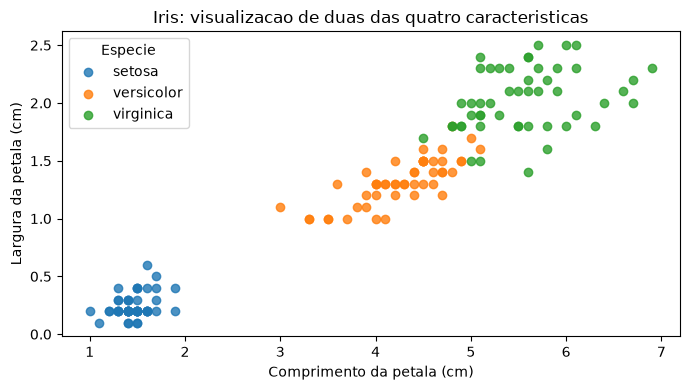

In [2]:
iris = load_iris()
X = iris.data
y = iris.target

print(f'Formato de X: {X.shape}')
print(f'Caracteristicas: {iris.feature_names}')
for indice, especie in enumerate(iris.target_names):
    print(f'Classe {indice}: {especie} ({np.sum(y == indice)} amostras)')

fig, ax = plt.subplots(figsize=(7, 4))
for indice, especie in enumerate(iris.target_names):
    ax.scatter(X[y == indice, 2], X[y == indice, 3], label=especie, alpha=0.8)
ax.set(xlabel='Comprimento da petala (cm)', ylabel='Largura da petala (cm)',
       title='Iris: visualizacao de duas das quatro caracteristicas')
ax.legend(title='Especie')
plt.tight_layout()
plt.show()


## 3. Separar treino e teste

Reservamos **80% para treino** e **20% para teste**. O argumento `stratify=y` preserva a proporcao das especies nos dois conjuntos. A semente fixa torna a divisao reproduzivel.

O teste sera usado apenas na avaliacao final, nao para ajustar a rede ou escolher hiperparametros.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

print(f'Amostras de treino: {len(X_train)}')
print(f'Amostras de teste: {len(X_test)}')


Amostras de treino: 120
Amostras de teste: 30


## 4. Classificadores, aumento de dados e validacao cruzada

Usamos **StratifiedKFold com 5 folds**, uma variante do K-Fold que preserva a proporcao das especies. Em cada rodada, 96 flores originais treinam o modelo e 24 validam. Os mesmos folds sao usados com e sem aumento de dados. As 30 flores de teste ficam fora desse processo.

O aumento gera **duas copias sinteticas por flor**, com ruido gaussiano de desvio igual a **5% do desvio padrao de cada caracteristica do treino do fold**. Os rotulos sao mantidos e as medidas sao limitadas a valores positivos. Os parametros abaixo podem ser alterados.

**Sem vazamento:** primeiro separamos os folds, depois geramos as copias apenas do treino. A padronizacao tambem e ajustada apenas nesse treino. Validacao e teste nunca recebem dados sinteticos.

Esse ruido simula pequenas variacoes nas medidas, mas nao garante flores biologicamente plausiveis ou melhor desempenho. Copias sinteticas nao sao observacoes independentes.

### Como funciona o VQC

O circuito usa **4 qubits**, inicialmente em zero, e codifica as quatro entradas com portas RY (`AngleEmbedding`). Antes disso, aplicamos `StandardScaler` e a transformacao fixa `2 * arctan(x)`, que limita os angulos a (-pi, pi). Apenas o scaler aprende estatisticas, sempre do treino de cada fold.

Cada camada `StronglyEntanglingLayers` tem tres rotacoes treinaveis por qubit e portas CNOT entre qubits. Com duas camadas, sao **24 parametros treinaveis**. Medimos os qubits 0 e 1: as probabilidades de 00, 01 e a soma das probabilidades de 10 e 11 representam, respectivamente, setosa, versicolor e virginica. Esse agrupamento e fixo e assimetrico; nao existe uma camada classica treinavel de saida.

O PyTorch calcula gradientes por `backprop` atraves do simulador `default.qubit`. Adam minimiza a entropia cruzada das probabilidades das classes. A simulacao e ideal, em CPU, sem ruido e sem amostragem finita (`shots=None`); nao requer hardware quantico nem demonstra vantagem quantica. O aumento de dados continua sendo classico.

### VQC2: quatro features em dois qubits

A opcao `'vqc2'` mantem as quatro entradas, mas codifica duas por qubit em eixos diferentes, apos o mesmo pre-processamento:

| Qubit | RY | RZ (apos RY) |
| --- | --- | --- |
| 0 | Comprimento da petala (feature 2) | Largura da petala (feature 3) |
| 1 | Comprimento da sepala (feature 0) | Largura da sepala (feature 1) |

O par das petalas e fortemente correlacionado (aproximadamente 0,963 no Iris completo). As sepalas sao o par restante, com correlacao fraca (aproximadamente -0,118), nao outro par fortemente correlacionado. Esse agrupamento e uma hipotese fixa fornecida para o experimento, nao uma escolha automatica dentro dos folds; para estimar seu beneficio, use novos dados ou um protocolo que considere essa exploracao previa.

RY seguida de RZ evita reduzir as duas features a uma simples soma de angulos, como ocorreria com duas RY consecutivas. Isso nao garante uma codificacao sem ambiguidades nem que correlacao classica gere vantagem quantica. Nao fazemos media ou descarte de features.

Depois da codificacao, usamos `StronglyEntanglingLayers` nos dois qubits, com **12 parametros treinaveis** para duas camadas. Em geral, sao `3 * n_qubits * VQC_CAMADAS` parametros: com cinco camadas, por exemplo, o VQC2 usa 30 e o VQC usa 60. A leitura permanece `P(00)`, `P(01)` e `P(10) + P(11)` para as tres especies. Adam, perda, folds e aumento de dados sao os mesmos do VQC de quatro qubits.

### VQC3: tres qubits e 30 parametros

Na opcao `'vqc3'`, o primeiro qubit continua recebendo as duas features fortemente correlacionadas da petala, mas cada medida da sepala fica em um qubit separado:

| Qubit (indice no codigo) | Codificacao |
| --- | --- |
| Primeiro (0) | RY: comprimento da petala; depois RZ: largura da petala |
| Segundo (1) | RY: comprimento da sepala |
| Terceiro (2) | RY: largura da sepala |

As medidas da sepala tem correlacao linear fraca entre si, nao necessariamente independencia estatistica. O agrupamento e fixo, sem estimar correlacoes no teste. Mantemos as quatro features e o mesmo pre-processamento.

Para manter **30 parametros treinaveis**, usamos **3 camadas completas** de `StronglyEntanglingLayers` (3 x 3 x 3 = 27), mais uma **RY treinavel em cada qubit** (3 parametros), seguidas de um anel de CNOTs 0->1->2->0. A leitura de classes continua `P(00)`, `P(01)` e `P(10) + P(11)` nos qubits 0 e 1, marginalizando o terceiro qubit. A estrutura de `'vqc3'` e fixa e nao depende de `VQC_CAMADAS`.

Cada VQC faz **11 treinamentos** neste fluxo (5 folds com e sem aumento, mais o treino final), por isso pode demorar mais que a MLP. Reduza `VQC_EPOCAS` para um teste rapido; isso pode prejudicar a convergencia. A validacao escolhe apenas usar ou nao aumento para o modelo selecionado, nao escolhe automaticamente entre arquiteturas.

In [4]:
N_FOLDS = 5
N_COPIAS = 2
NIVEL_RUIDO = 0.05

def aumentar_dados(X_original, y_original, n_copias, nivel_ruido, seed):
    rng = np.random.default_rng(seed)
    escala = X_original.std(axis=0) * nivel_ruido
    copias = np.tile(X_original, (n_copias, 1))
    sinteticos = np.maximum(
        copias + rng.normal(0, escala, size=copias.shape), 1e-6
    )
    return (
        np.concatenate([X_original, sinteticos]),
        np.concatenate([y_original, np.tile(y_original, n_copias)]),
    )

class ClassificadorVQC(ClassifierMixin, BaseEstimator):
    def __init__(self, n_camadas=2, epocas=120, taxa_aprendizado=0.05, random_state=42, n_qubits=4, camada_parcial=False, par_features=(2, 3)):
        self.n_camadas = n_camadas
        self.epocas = epocas
        self.taxa_aprendizado = taxa_aprendizado
        self.random_state = random_state
        self.n_qubits = n_qubits
        self.camada_parcial = camada_parcial
        self.par_features = par_features

    def _probabilidades(self, entradas):
        import torch

        medidas = self.circuit_(entradas, self.pesos_)
        probabilidades = torch.stack(
            [medidas[..., 0], medidas[..., 1], medidas[..., 2] + medidas[..., 3]],
            dim=-1,
        )
        # Evita log(0), mantendo as probabilidades normalizadas.
        probabilidades = probabilidades.clamp(min=1e-12)
        return probabilidades / probabilidades.sum(dim=-1, keepdim=True)

    def fit(self, X, y):
        try:
            import pennylane as qml
            import torch
        except ImportError as erro:
            raise ImportError('Para usar o VQC, execute %pip install pennylane torch') from erro

        X, y = check_X_y(X, y, dtype=float)
        if X.shape[1] != 4:
            raise ValueError('Este circuito espera exatamente quatro caracteristicas.')
        if self.n_camadas < 1 or self.epocas < 1 or self.taxa_aprendizado <= 0:
            raise ValueError('Camadas, epocas e taxa de aprendizado devem ser positivos.')
        if self.n_qubits not in (2, 3, 4):
            raise ValueError('Escolha dois, tres ou quatro qubits para estas codificacoes.')
        if self.camada_parcial and (self.n_qubits, self.n_camadas) not in ((3, 3), (4, 2)):
            raise ValueError('A variante parcial usa (qubits, camadas) = (3, 3) ou (4, 2).')
        if self.n_qubits == 3:
            if (len(self.par_features) != 2
                    or any(not isinstance(i, (int, np.integer)) or isinstance(i, (bool, np.bool_))
                           or not 0 <= i < 4 for i in self.par_features)
                    or self.par_features[0] == self.par_features[1]):
                raise ValueError('par_features deve conter dois indices inteiros distintos entre 0 e 3.')
            self.ordem_features_ = tuple(self.par_features) + tuple(
                i for i in range(4) if i not in self.par_features
            )
        self.classes_, indices = np.unique(y, return_inverse=True)
        if len(self.classes_) != 3:
            raise ValueError('Este VQC foi definido para exatamente tres classes.')
        self.n_features_in_ = X.shape[1]
        dispositivo = qml.device('default.qubit', wires=self.n_qubits, shots=None)

        @qml.qnode(dispositivo, interface='torch', diff_method='backprop')
        def circuito(entradas, pesos):
            if self.n_qubits == 3:
                qml.RY(entradas[..., self.ordem_features_[0]], wires=0)
                qml.RZ(entradas[..., self.ordem_features_[1]], wires=0)
                qml.RY(entradas[..., self.ordem_features_[2]], wires=1)
                qml.RY(entradas[..., self.ordem_features_[3]], wires=2)
            elif self.n_qubits == 2:
                # No VQC2, petalas no qubit 0 e sepalas no qubit 1.
                qml.RY(entradas[..., 2], wires=0)
                qml.RZ(entradas[..., 3], wires=0)
                qml.RY(entradas[..., 0], wires=1)
                qml.RZ(entradas[..., 1], wires=1)
            else:
                qml.AngleEmbedding(entradas, wires=range(4), rotation='Y')
            if self.camada_parcial:
                n_completos = 3 * self.n_qubits * self.n_camadas
                qml.StronglyEntanglingLayers(
                    pesos[:n_completos].reshape(self.n_camadas, self.n_qubits, 3),
                    wires=range(self.n_qubits),
                )
                for qubit in range(self.n_qubits):
                    qml.RY(pesos[n_completos + qubit], wires=qubit)
                if self.n_qubits == 4:
                    qml.RX(pesos[28], wires=0)
                    qml.RX(pesos[29], wires=1)
                for qubit in range(self.n_qubits):
                    qml.CNOT(wires=[qubit, (qubit + 1) % self.n_qubits])
            else:
                qml.StronglyEntanglingLayers(pesos, wires=range(self.n_qubits))
            return qml.probs(wires=[0, 1])

        self.circuit_ = circuito
        rng = np.random.default_rng(self.random_state)
        formato_pesos = (30,) if self.camada_parcial else (self.n_camadas, self.n_qubits, 3)
        self.pesos_ = torch.nn.Parameter(torch.tensor(
            rng.uniform(-np.pi, np.pi, size=formato_pesos),
            dtype=torch.float64,
        ))
        entradas = torch.tensor(X, dtype=torch.float64)
        rotulos = torch.tensor(indices, dtype=torch.long)
        otimizador = torch.optim.Adam([self.pesos_], lr=self.taxa_aprendizado)
        self.loss_curve_ = []
        for _ in range(self.epocas):
            otimizador.zero_grad()
            perda = torch.nn.functional.nll_loss(self._probabilidades(entradas).log(), rotulos)
            perda.backward()
            otimizador.step()
            with torch.no_grad():
                perda_atual = torch.nn.functional.nll_loss(
                    self._probabilidades(entradas).log(), rotulos
                )
                self.loss_curve_.append(perda_atual.item())
        self.n_iter_ = len(self.loss_curve_)
        self.loss_ = self.loss_curve_[-1]
        return self

    def predict_proba(self, X):
        import torch

        check_is_fitted(self, ['pesos_', 'circuit_', 'loss_'])
        X = check_array(X, dtype=float)
        if X.shape[1] != self.n_features_in_:
            raise ValueError('Numero de caracteristicas diferente do treino.')
        with torch.no_grad():
            return self._probabilidades(torch.tensor(X, dtype=torch.float64)).numpy()

    def predict(self, X):
        return self.classes_[np.argmax(self.predict_proba(X), axis=1)]


def criar_modelo(n_amostras, tipo_modelo=None, seed=SEED):
    tipo_modelo = TIPO_MODELO if tipo_modelo is None else tipo_modelo
    if tipo_modelo in ('vqc', 'vqc2', 'vqc3', 'vqc30'):
        return Pipeline([
            ('padronizacao', StandardScaler()),
            ('angulos', FunctionTransformer(lambda X: 2 * np.arctan(X))),
            ('rede', ClassificadorVQC(
                n_camadas={'vqc3': 3, 'vqc30': 2}.get(tipo_modelo, VQC_CAMADAS),
                epocas=VQC_EPOCAS,
                taxa_aprendizado=VQC_TAXA_APRENDIZADO, random_state=seed,
                n_qubits={'vqc2': 2, 'vqc3': 3}.get(tipo_modelo, 4),
                camada_parcial=tipo_modelo in ('vqc3', 'vqc30'),
            )),
        ])
    if tipo_modelo != 'mlp':
        raise ValueError("TIPO_MODELO deve ser 'mlp', 'vqc', 'vqc2', 'vqc3' ou 'vqc30'.")
    return Pipeline([
        ('padronizacao', StandardScaler()),
        ('rede', MLPClassifier(
            hidden_layer_sizes=(16, 8),
            activation='relu',
            solver='adam',
            learning_rate_init=0.01,
            alpha=0.001,
            batch_size=n_amostras,
            max_iter=2000,
            tol=1e-4,
            n_iter_no_change=50,
            random_state=seed,
        )),
    ])


Classificador selecionado: VQC2


Fold 1 | Sem aumento | treino= 96 | acuracia=79.17% | F1 macro=0.7890


Fold 1 | Com aumento | treino=288 | acuracia=79.17% | F1 macro=0.7890


Fold 2 | Sem aumento | treino= 96 | acuracia=70.83% | F1 macro=0.7111


Fold 2 | Com aumento | treino=288 | acuracia=75.00% | F1 macro=0.7547


...

Fold 3 | Com aumento | treino=288 | acuracia=83.33% | F1 macro=0.8342


Fold 4 | Sem aumento | treino= 96 | acuracia=66.67% | F1 macro=0.6667


Fold 4 | Com aumento | treino=288 | acuracia=66.67% | F1 macro=0.6667


Fold 5 | Sem aumento | treino= 96 | acuracia=95.83% | F1 macro=0.9582


Fold 5 | Com aumento | treino=288 | acuracia=95.83% | F1 macro=0.9582

Resumo: media +/- desvio padrao amostral entre folds
Sem aumento | acuracia: 0.7917 +/- 0.1141
Sem aumento | f1_macro: 0.7918 +/- 0.1136
Com aumento | acuracia: 0.8000 +/- 0.1079
Com aumento | f1_macro: 0.8006 +/- 0.1074


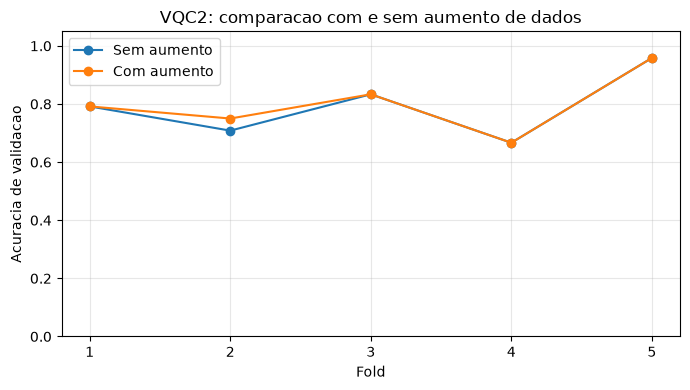

In [5]:
print(f'Classificador selecionado: {TIPO_MODELO.upper()}')
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
resultados = {
    'Sem aumento': {'acuracia': [], 'f1_macro': []},
    'Com aumento': {'acuracia': [], 'f1_macro': []},
}

for fold, (idx_treino, idx_validacao) in enumerate(cv.split(X_train, y_train), 1):
    X_fold, y_fold = X_train[idx_treino], y_train[idx_treino]
    X_val, y_val = X_train[idx_validacao], y_train[idx_validacao]
    for nome, metricas in resultados.items():
        X_fit, y_fit = X_fold, y_fold
        if nome == 'Com aumento':
            X_fit, y_fit = aumentar_dados(
                X_fold, y_fold, N_COPIAS, NIVEL_RUIDO, SEED + fold
            )
        modelo_fold = criar_modelo(len(X_fit))
        modelo_fold.fit(X_fit, y_fit)
        pred_val = modelo_fold.predict(X_val)
        acuracia = accuracy_score(y_val, pred_val)
        f1 = f1_score(y_val, pred_val, average='macro')
        metricas['acuracia'].append(acuracia)
        metricas['f1_macro'].append(f1)
        print(f'Fold {fold} | {nome:11s} | treino={len(X_fit):3d} | '
              f'acuracia={acuracia:.2%} | F1 macro={f1:.4f}')

print('\nResumo: media +/- desvio padrao amostral entre folds')
for nome, metricas in resultados.items():
    for metrica, valores in metricas.items():
        print(f'{nome} | {metrica}: '
              f'{np.mean(valores):.4f} +/- {np.std(valores, ddof=1):.4f}')

fig, ax = plt.subplots(figsize=(7, 4))
for nome, metricas in resultados.items():
    ax.plot(range(1, N_FOLDS + 1), metricas['acuracia'], marker='o', label=nome)
ax.set(xlabel='Fold', ylabel='Acuracia de validacao',
       title=f'{TIPO_MODELO.upper()}: comparacao com e sem aumento de dados',
       xticks=range(1, N_FOLDS + 1), ylim=(0, 1.05))
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 5. Treinar a configuracao final

Escolhemos a configuracao pela **maior acuracia media na validacao cruzada**. Em caso de empate numerico, preferimos nao aumentar os dados. O F1 macro e reportado como metrica complementar. O resultado da configuracao escolhida na validacao pode ser otimista por ter orientado a escolha; o teste reservado fornece a avaliacao final.

Na opcao **MLP**, a arquitetura possui 4 entradas, duas camadas ocultas com 16 e 8 neuronios, ativacao ReLU e saida softmax para as 3 classes. Adam ajusta os pesos com entropia cruzada e regularizacao L2. Nas opcoes **VQC** e **VQC2**, usamos os circuitos descritos anteriormente, com Adam e entropia cruzada, sem regularizacao L2.

O `StandardScaler` transforma cada entrada para ter media zero e desvio padrao unitario no treino. A `Pipeline` garante que essa transformacao seja aprendida **somente com os dados de treino** e reaplicada automaticamente nas previsoes.

Na MLP, `max_iter` limita o numero de epocas, mas o treino pode terminar antes conforme `tol` e `n_iter_no_change`. O VQC usa o numero fixo de epocas definido em `VQC_EPOCAS`. Ambos usam o conjunto de treino inteiro como um unico lote por epoca.

Configuracao escolhida: Com aumento
Amostras no treinamento final: 360


Epocas realizadas: 120
Perda final de treino: 0.5195


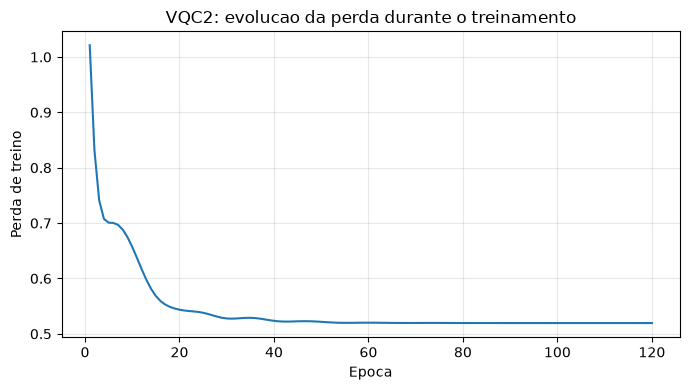

In [6]:
media_sem = np.mean(resultados['Sem aumento']['acuracia'])
media_com = np.mean(resultados['Com aumento']['acuracia'])
usar_aumento = bool(media_com > media_sem and not np.isclose(media_com, media_sem))
X_final, y_final = X_train, y_train
if usar_aumento:
    X_final, y_final = aumentar_dados(
        X_train, y_train, N_COPIAS, NIVEL_RUIDO, SEED
    )
print('Configuracao escolhida:', 'Com aumento' if usar_aumento else 'Sem aumento')
print(f'Amostras no treinamento final: {len(X_final)}')
modelo = criar_modelo(len(X_final))
modelo.fit(X_final, y_final)
rede = modelo.named_steps['rede']
print(f'Epocas realizadas: {rede.n_iter_}')
print(f'Perda final de treino: {rede.loss_:.4f}')

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(rede.loss_curve_) + 1), rede.loss_curve_)
ax.set(xlabel='Epoca', ylabel='Perda de treino',
       title=f'{TIPO_MODELO.upper()}: evolucao da perda durante o treinamento')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Circuito quantico treinado

Se o VQC estiver selecionado, o desenho abaixo mostra as portas de codificacao, rotacoes e CNOTs com os parametros finais. Para facilitar a leitura, usamos angulos de entrada iguais a zero apenas no desenho; as previsoes usam as medidas transformadas de cada flor.

In [7]:
if TIPO_MODELO in ('vqc', 'vqc2', 'vqc3', 'vqc30'):
    import pennylane as qml
    import torch

    print(f'Qubits: {rede.n_qubits} | Parametros quanticos treinaveis: {rede.pesos_.numel()}')
    print(qml.draw(rede.circuit_, level='device')(
        torch.zeros(4, dtype=torch.float64), rede.pesos_.detach()
    ))
else:
    print("Para visualizar o circuito, selecione 'vqc', 'vqc2', 'vqc3' ou 'vqc30' e execute tudo novamente.")


Qubits: 2 | Parametros quanticos treinaveis: 30
0: ──RY(0.00)──RZ(0.00)──Rot(2.04,-0.82,2.82)─╭●─╭X──Rot(1.33,2.10,-2.57)──╭●─╭X ···
1: ──RY(0.00)──RZ(0.00)──Rot(1.98,-2.85,2.68)─╰X─╰●──Rot(-0.12,-1.39,2.82)─╰X─╰● ···

0: ··· ──Rot(1.04,2.02,-0.93)──╭●─╭X──Rot(2.16,1.19,1.80)──╭●─╭X──Rot(2.45,-2.43,-0.21)─╭●─╭X─┤ ···
1: ··· ──Rot(-1.94,0.13,-2.63)─╰X─╰●──Rot(-0.75,2.59,3.17)─╰X─╰●──Rot(-2.51,-2.64,1.15)─╰X─╰●─┤ ···

0: ···  ╭Probs
1: ···  ╰Probs


## 6. Avaliar no conjunto de teste

A **acuracia** mede a proporcao de previsoes corretas. O relatorio apresenta precisao, revocacao (recall) e F1 por especie. Na matriz de confusao, a diagonal principal representa os acertos.

A perda de treino baixa, sozinha, nao garante boa generalizacao. Por isso, avaliamos tambem amostras que a rede nao viu durante o treinamento.

Acuracia no teste: 76.67%
              precision    recall  f1-score   support

      setosa       1.00      0.80      0.89        10
  versicolor       0.78      0.70      0.74        10
   virginica       0.62      0.80      0.70        10

    accuracy                           0.77        30
   macro avg       0.80      0.77      0.77        30
weighted avg       0.80      0.77      0.77        30



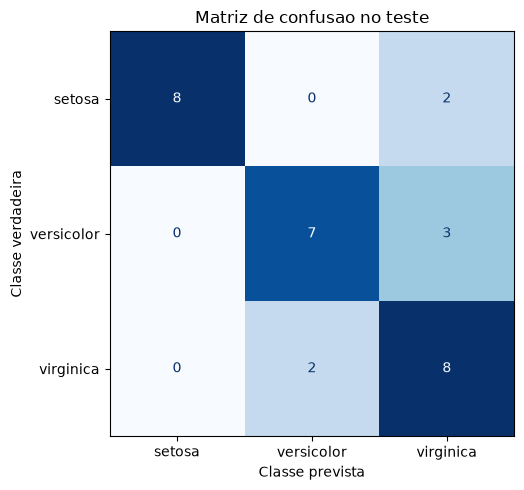

In [8]:
y_pred = modelo.predict(X_test)

print(f'Acuracia no teste: {accuracy_score(y_test, y_pred):.2%}')
print(classification_report(
    y_test, y_pred, labels=rede.classes_,
    target_names=iris.target_names, zero_division=0,
))

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=rede.classes_, display_labels=iris.target_names,
    cmap='Blues', colorbar=False, ax=ax,
)
ax.set(title='Matriz de confusao no teste',
       xlabel='Classe prevista', ylabel='Classe verdadeira')
plt.tight_layout()
plt.show()


## 7. Classificar uma nova flor

Informe as quatro medidas na mesma ordem do dataset: comprimento da sepala, largura da sepala, comprimento da petala e largura da petala, em centimetros. As probabilidades sao estimativas do modelo, nao garantias de acerto.

In [9]:
nova_flor = np.array([[5.1, 3.5, 1.4, 0.2]])
classe_prevista = modelo.predict(nova_flor)[0]
probabilidades = modelo.predict_proba(nova_flor)[0]

print(f'Especie prevista: {iris.target_names[classe_prevista]}')
for classe, probabilidade in zip(rede.classes_, probabilidades):
    print(f'{iris.target_names[classe]}: {probabilidade:.2%}')


Especie prevista: setosa
setosa: 71.54%
versicolor: 8.25%
virginica: 20.21%


## 8. Experimento: dois, tres e quatro qubits com 30 parametros

Comparamos tres arquiteturas com o mesmo numero nominal de parametros treinaveis:

| Modelo | Qubits | Estrutura variacional | Parametros |
| --- | --- | --- | --- |
| VQC2-30 | 2 | 5 camadas completas | 5 x 2 x 3 = 30 |
| VQC3-30 (`vqc3`) | 3 | 3 camadas completas + 3 RY | 3 x 3 x 3 + 3 = 30 |
| VQC4-30 (`vqc30`) | 4 | 2 camadas completas + camada parcial | 2 x 4 x 3 + 6 = 30 |

No VQC3-30, a camada parcial aplica **RY em cada um dos tres qubits**, seguidas de um anel de CNOTs 0->1->2->0. As petalas continuam juntas no qubit 0 e as sepalas ficam separadas nos qubits 1 e 2.

No VQC4-30, a camada parcial aplica **RY em cada um dos quatro qubits**, depois **RX nos qubits 0 e 1**, seguidas de um anel de CNOTs 0->1->2->3->0. Usamos RX, e nao RZ finais, para evitar adicionar apenas fases que nao alterariam as probabilidades apos portas CNOT. Todas as rotacoes parciais sao treinaveis; os angulos de entrada e as CNOTs nao entram na contagem. `vqc3` e `vqc30` sempre usam essas estruturas fixas, independentemente de `VQC_CAMADAS`.

**Protocolo controlado:** os mesmos folds estratificados sobre `X_train`, as mesmas amostras sinteticas, sementes de inicializacao, Adam, taxa de aprendizado, epocas e leitura de classes para os tres modelos. As cinco camadas do VQC2 sao fixadas explicitamente neste experimento, mesmo se `VQC_CAMADAS` mudar. O scaler e ajustado do zero em cada treinamento.

Repetimos os folds para cada semente de `EXPERIMENTO_SEMENTES`, variando apenas a inicializacao dos pesos. A divisao dos folds e o ruido de aumento permanecem fixos. Com 5 folds, 3 sementes e as duas condicoes de aumento, sao **90 treinamentos adicionais**. Para um teste rapido, use uma unica semente; para pular, defina `EXECUTAR_EXPERIMENTO_30 = False`.

Reportamos acuracia, F1 macro, tempo de ajuste e diferencas pareadas entre os tres pares de modelos. **O experimento nao consulta `X_test` nem `y_test` e nao troca o classificador do fluxo principal.** Nenhum vencedor e escolhido pelo resultado do teste.

O mesmo numero de parametros nao iguala expressividade, profundidade, numero de portas ou custo computacional. A comparacao altera tambem a codificacao das features e o emaranhamento, portanto nao isola apenas o efeito do numero de qubits. Os escores entre folds e sementes nao sao observacoes independentes; o desvio padrao e descritivo, nao um intervalo de confianca. Tempos sao de simulacao classica e dependem da maquina.

VQC2-30 | fold=1 | seed=42 | aumento=False | acuracia=79.17% | 2.14s


VQC3-30 | fold=1 | seed=42 | aumento=False | acuracia=95.83% | 2.59s


VQC4-30 | fold=1 | seed=42 | aumento=False | acuracia=87.50% | 2.40s


VQC2-30 | fold=1 | seed=43 | aumento=False | acuracia=79.17% | 2.39s


VQC3-30 | fold=1 | seed=43 | aumento=False | acuracia=87.50% | 2.37s


...

VQC3-30 | fold=5 | seed=43 | aumento=True | acuracia=91.67% | 2.66s


VQC4-30 | fold=5 | seed=43 | aumento=True | acuracia=83.33% | 2.87s


VQC2-30 | fold=5 | seed=44 | aumento=True | acuracia=95.83% | 2.55s


VQC3-30 | fold=5 | seed=44 | aumento=True | acuracia=91.67% | 2.84s


VQC4-30 | fold=5 | seed=44 | aumento=True | acuracia=87.50% | 2.72s

Resumo: media +/- desvio padrao amostral entre folds e sementes
VQC2-30 | aumento=False | n=15 | acuracia=79.17% +/- 10.56% | F1=0.7918 +/- 0.1052 | tempo medio=2.21s
VQC3-30 | aumento=False | n=15 | acuracia=90.00% +/- 4.67% | F1=0.8998 +/- 0.0465 | tempo medio=2.40s
VQC4-30 | aumento=False | n=15 | acuracia=89.72% +/- 4.69% | F1=0.8931 +/- 0.0502 | tempo medio=2.50s
VQC2-30 | aumento=True | n=15 | acuracia=80.00% +/- 9.99% | F1=0.8006 +/- 0.0994 | tempo medio=2.31s
VQC3-30 | aumento=True | n=15 | acuracia=89.72% +/- 3.47% | F1=0.8968 +/- 0.0353 | tempo medio=2.56s
VQC4-30 | aumento=True | n=15 | acuracia=88.89% +/- 3.75% | F1=0.8842 +/- 0.0408 | tempo medio=2.75s
Diferenca pareada VQC3-30 - VQC2-30 | aumento=False | acuracia: +0.1083 +/- 0.1155
Diferenca pareada VQC3-30 - VQC2-30 | aumento=False | f1_macro: +0.1080 +/- 0.1151
Diferenca pareada VQC4-30 - VQC2-30 | aumento=False | acuracia: +0.1056 +/- 0.1399
Diferenc

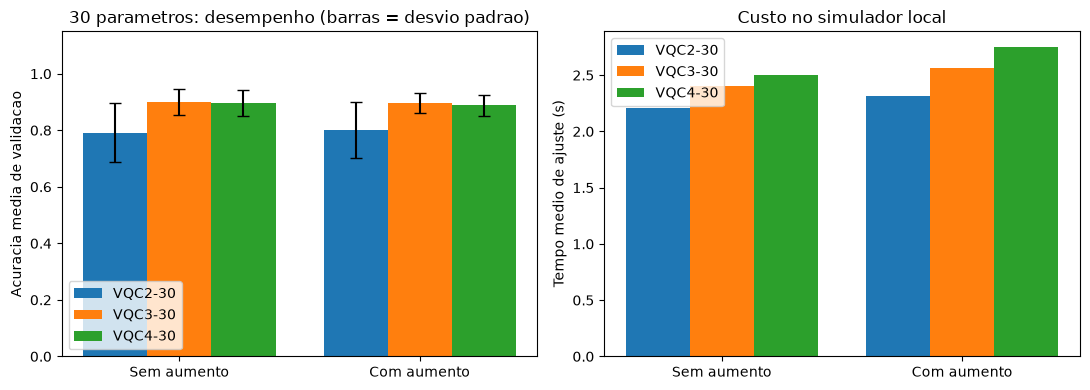

In [10]:
resultados_30 = []
resumo_30 = []
if EXECUTAR_EXPERIMENTO_30:
    if not EXPERIMENTO_SEMENTES or len(set(EXPERIMENTO_SEMENTES)) != len(EXPERIMENTO_SEMENTES):
        raise ValueError('Informe ao menos uma semente, sem repeticoes.')
    modelos_30 = [('VQC2-30', 'vqc2'), ('VQC3-30', 'vqc3'), ('VQC4-30', 'vqc30')]
    cv_30 = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    for fold, (idx_treino, idx_val) in enumerate(cv_30.split(X_train, y_train), 1):
        for aumento in (False, True):
            X_fit, y_fit = X_train[idx_treino], y_train[idx_treino]
            if aumento:
                X_fit, y_fit = aumentar_dados(
                    X_fit, y_fit, N_COPIAS, NIVEL_RUIDO, SEED + fold
                )
            for semente in EXPERIMENTO_SEMENTES:
                for nome, tipo in modelos_30:
                    candidato = criar_modelo(len(X_fit), tipo_modelo=tipo, seed=semente)
                    if tipo == 'vqc2':
                        candidato.set_params(rede__n_camadas=5)
                    inicio = perf_counter()
                    candidato.fit(X_fit, y_fit)
                    segundos = perf_counter() - inicio
                    parametros = candidato.named_steps['rede'].pesos_.numel()
                    assert parametros == 30, f'{nome}: esperado 30, recebido {parametros}'
                    predicao = candidato.predict(X_train[idx_val])
                    registro = dict(
                        modelo=nome, aumento=aumento, fold=fold, seed=semente,
                        parametros=parametros, segundos=segundos,
                        acuracia=accuracy_score(y_train[idx_val], predicao),
                        f1_macro=f1_score(y_train[idx_val], predicao, average='macro'),
                    )
                    resultados_30.append(registro)
                    print(f'{nome} | fold={fold} | seed={semente} | aumento={aumento} | '
                          f'acuracia={registro["acuracia"]:.2%} | {segundos:.2f}s')

    print('\nResumo: media +/- desvio padrao amostral entre folds e sementes')
    for aumento in (False, True):
        for nome, _ in modelos_30:
            grupo = [r for r in resultados_30 if r['modelo'] == nome and r['aumento'] == aumento]
            resumo = dict(modelo=nome, aumento=aumento, n=len(grupo))
            for metrica in ('acuracia', 'f1_macro', 'segundos'):
                valores = [r[metrica] for r in grupo]
                resumo[metrica] = np.mean(valores)
                resumo[metrica + '_std'] = np.std(valores, ddof=1)
            resumo_30.append(resumo)
            print(f'{nome} | aumento={aumento} | n={len(grupo)} | '
                  f'acuracia={resumo["acuracia"]:.2%} +/- {resumo["acuracia_std"]:.2%} | '
                  f'F1={resumo["f1_macro"]:.4f} +/- {resumo["f1_macro_std"]:.4f} | '
                  f'tempo medio={resumo["segundos"]:.2f}s')

    for aumento in (False, True):
        pares = {}
        for r in resultados_30:
            if r['aumento'] == aumento:
                pares.setdefault((r['fold'], r['seed']), {})[r['modelo']] = r
        for indice, (referencia, _) in enumerate(modelos_30):
            for comparado, _ in modelos_30[indice + 1:]:
                for metrica in ('acuracia', 'f1_macro'):
                    diferencas = [p[comparado][metrica] - p[referencia][metrica] for p in pares.values()]
                    print(f'Diferenca pareada {comparado} - {referencia} | aumento={aumento} | {metrica}: '
                          f'{np.mean(diferencas):+.4f} +/- {np.std(diferencas, ddof=1):.4f}')

    fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
    posicoes = np.arange(2)
    largura = 0.8 / len(modelos_30)
    for indice, (nome, _) in enumerate(modelos_30):
        grupo = [r for r in resumo_30 if r['modelo'] == nome]
        deslocamento = (indice - (len(modelos_30) - 1) / 2) * largura
        eixos[0].bar(posicoes + deslocamento, [r['acuracia'] for r in grupo],
                     yerr=[r['acuracia_std'] for r in grupo], width=largura, capsize=4, label=nome)
        eixos[1].bar(posicoes + deslocamento, [r['segundos'] for r in grupo],
                     width=largura, label=nome)
    for ax in eixos:
        ax.set_xticks(posicoes, ['Sem aumento', 'Com aumento'])
        ax.legend()
    eixos[0].set(ylabel='Acuracia media de validacao', ylim=(0, 1.15),
                 title='30 parametros: desempenho (barras = desvio padrao)')
    eixos[1].set(ylabel='Tempo medio de ajuste (s)', title='Custo no simulador local')
    plt.tight_layout()
    plt.show()
else:
    print('Experimento de 30 parametros desativado na configuracao.')


## 9. Ablacao do agrupamento de features no VQC3

Para investigar o papel do agrupamento, mantemos o **mesmo circuito VQC3 de 30 parametros**: 3 camadas completas, 3 RY adicionais, o mesmo emaranhamento e a mesma leitura de classes. Alteramos apenas a associacao das quatro features as quatro portas de codificacao.

| Configuracao | Qubit 0: RY | Qubit 0: RZ | Qubit 1: RY | Qubit 2: RY |
| --- | --- | --- | --- | --- |
| Petalas (referencia) | Comprimento petala (2) | Largura petala (3) | Comprimento sepala (0) | Largura sepala (1) |
| Sepalas | Comprimento sepala (0) | Largura sepala (1) | Comprimento petala (2) | Largura petala (3) |
| Comprimentos | Comprimento petala (2) | Comprimento sepala (0) | Largura sepala (1) | Largura petala (3) |
| Larguras | Largura petala (3) | Largura sepala (1) | Comprimento sepala (0) | Comprimento petala (2) |

O parametro `rede__par_features=(a, b)` define quais features entram em RY e RZ do qubit 0, nessa ordem. As duas restantes entram em RY nos qubits 1 e 2, na ordem dos indices originais. O padrao `(2, 3)` preserva o VQC3 anterior.

**Controles:** usamos os mesmos folds de treino da secao 8, cinco sementes por padrao (`ABLACAO_SEMENTES`), os mesmos pesos iniciais para uma dada semente, `VQC_EPOCAS`, Adam e taxa de aprendizado. Cada pipeline ajusta seu scaler apenas no treino do fold. **Nao usamos aumento de dados nesta ablacao**, para nao misturar o efeito do agrupamento com o do ruido sintetico. Assim, as comparacoes sao pareadas por fold e semente.

Com 4 agrupamentos, 5 folds e 5 sementes, sao **100 treinamentos adicionais**. Para pular, defina `EXECUTAR_ABLACAO_VQC3 = False`; para um teste rapido, reduza `ABLACAO_SEMENTES` ou `VQC_EPOCAS`. Reportamos media e desvio padrao de acuracia e F1 macro, tempo e diferencas em relacao ao agrupamento das petalas. O experimento nao acessa o teste, nao escolhe automaticamente um vencedor e nao altera o modelo principal.

**Interpretacao:** a associacao das features aos eixos RY/RZ e aos qubits tambem muda. Portanto, isto compara quatro codificacoes especificas, nao prova que a correlacao seja a causa de uma diferenca. Nao e uma busca exaustiva de todos os pares e ordens de rotacao. Como os experimentos anteriores motivaram essa escolha, os resultados sao exploratorios; escores de folds/sementes nao sao independentes e o desvio padrao nao e um intervalo de confianca. Uma conclusao confirmatoria exige um protocolo predefinido e dados independentes.

Petalas (referencia) | fold=1 | seed=42 | acuracia=95.83% | F1=0.9582


Sepalas | fold=1 | seed=42 | acuracia=95.83% | F1=0.9582


Comprimentos | fold=1 | seed=42 | acuracia=95.83% | F1=0.9582


Larguras | fold=1 | seed=42 | acuracia=95.83% | F1=0.9582


Petalas (referencia) | fold=1 | seed=43 | acuracia=87.50% | F1=0.8745


...

Larguras | fold=5 | seed=45 | acuracia=95.83% | F1=0.9582


Petalas (referencia) | fold=5 | seed=46 | acuracia=91.67% | F1=0.9153


Sepalas | fold=5 | seed=46 | acuracia=91.67% | F1=0.9153


Comprimentos | fold=5 | seed=46 | acuracia=91.67% | F1=0.9153


Larguras | fold=5 | seed=46 | acuracia=95.83% | F1=0.9582

Ablacao sem aumento: media +/- desvio padrao entre folds e sementes
Petalas (referencia) | n=25 | acuracia=90.00% +/- 4.50% | F1=0.8997 +/- 0.0449 | tempo medio=2.39s
Sepalas | n=25 | acuracia=95.00% +/- 3.18% | F1=0.9494 +/- 0.0326 | tempo medio=2.42s
Comprimentos | n=25 | acuracia=92.83% +/- 1.91% | F1=0.9279 +/- 0.0193 | tempo medio=2.44s
Larguras | n=25 | acuracia=94.67% +/- 4.08% | F1=0.9462 +/- 0.0415 | tempo medio=2.40s
Diferenca pareada Sepalas - Petalas | acuracia: +0.0500 +/- 0.0589
Diferenca pareada Sepalas - Petalas | f1_macro: +0.0497 +/- 0.0592
Diferenca pareada Comprimentos - Petalas | acuracia: +0.0283 +/- 0.0506
Diferenca pareada Comprimentos - Petalas | f1_macro: +0.0282 +/- 0.0508
Diferenca pareada Larguras - Petalas | acuracia: +0.0467 +/- 0.0529
Diferenca pareada Larguras - Petalas | f1_macro: +0.0465 +/- 0.0535


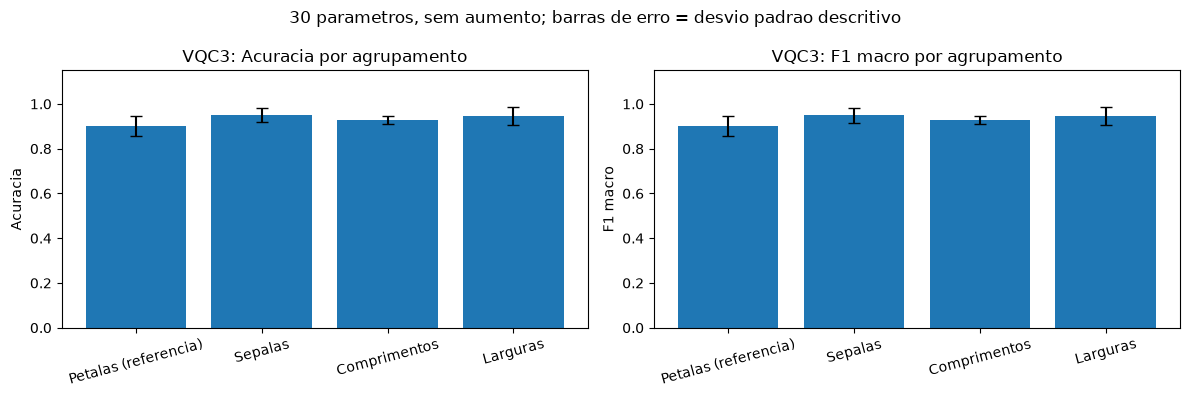

In [11]:
resultados_ablacao = []
resumo_ablacao = []
agrupamentos_vqc3 = [
    ('Petalas (referencia)', (2, 3)),
    ('Sepalas', (0, 1)),
    ('Comprimentos', (2, 0)),
    ('Larguras', (3, 1)),
]
if EXECUTAR_ABLACAO_VQC3:
    if not ABLACAO_SEMENTES or len(set(ABLACAO_SEMENTES)) != len(ABLACAO_SEMENTES):
        raise ValueError('Informe ao menos uma semente de ablacao, sem repeticoes.')
    cv_ablacao = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    for fold, (idx_treino, idx_val) in enumerate(cv_ablacao.split(X_train, y_train), 1):
        for semente in ABLACAO_SEMENTES:
            for nome, par in agrupamentos_vqc3:
                candidato = criar_modelo(len(idx_treino), tipo_modelo='vqc3', seed=semente)
                candidato.set_params(rede__par_features=par)
                inicio = perf_counter()
                candidato.fit(X_train[idx_treino], y_train[idx_treino])
                segundos = perf_counter() - inicio
                parametros = candidato.named_steps['rede'].pesos_.numel()
                assert parametros == 30, f'{nome}: esperado 30, recebido {parametros}'
                predicao = candidato.predict(X_train[idx_val])
                registro = dict(
                    agrupamento=nome, par=par, fold=fold, seed=semente,
                    parametros=parametros, segundos=segundos,
                    acuracia=accuracy_score(y_train[idx_val], predicao),
                    f1_macro=f1_score(y_train[idx_val], predicao, average='macro'),
                )
                resultados_ablacao.append(registro)
                print(f'{nome} | fold={fold} | seed={semente} | '
                      f'acuracia={registro["acuracia"]:.2%} | F1={registro["f1_macro"]:.4f}')

    print('\nAblacao sem aumento: media +/- desvio padrao entre folds e sementes')
    for nome, par in agrupamentos_vqc3:
        grupo = [r for r in resultados_ablacao if r['agrupamento'] == nome]
        resumo = dict(agrupamento=nome, par=par, n=len(grupo))
        for metrica in ('acuracia', 'f1_macro', 'segundos'):
            valores = [r[metrica] for r in grupo]
            resumo[metrica] = np.mean(valores)
            resumo[metrica + '_std'] = np.std(valores, ddof=1)
        resumo_ablacao.append(resumo)
        print(f'{nome} | n={len(grupo)} | '
              f'acuracia={resumo["acuracia"]:.2%} +/- {resumo["acuracia_std"]:.2%} | '
              f'F1={resumo["f1_macro"]:.4f} +/- {resumo["f1_macro_std"]:.4f} | '
              f'tempo medio={resumo["segundos"]:.2f}s')

    referencia = {(r['fold'], r['seed']): r for r in resultados_ablacao
                  if r['agrupamento'] == 'Petalas (referencia)'}
    for nome, _ in agrupamentos_vqc3[1:]:
        grupo = [r for r in resultados_ablacao if r['agrupamento'] == nome]
        for metrica in ('acuracia', 'f1_macro'):
            diferencas = [r[metrica] - referencia[(r['fold'], r['seed'])][metrica] for r in grupo]
            print(f'Diferenca pareada {nome} - Petalas | {metrica}: '
                  f'{np.mean(diferencas):+.4f} +/- {np.std(diferencas, ddof=1):.4f}')

    fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
    posicoes = np.arange(len(resumo_ablacao))
    for ax, metrica, titulo in zip(eixos, ('acuracia', 'f1_macro'), ('Acuracia', 'F1 macro')):
        ax.bar(posicoes, [r[metrica] for r in resumo_ablacao],
               yerr=[r[metrica + '_std'] for r in resumo_ablacao], capsize=4)
        ax.set_xticks(posicoes, [r['agrupamento'] for r in resumo_ablacao], rotation=15)
        ax.set(ylabel=titulo, ylim=(0, 1.15), title=f'VQC3: {titulo} por agrupamento')
    fig.suptitle('30 parametros, sem aumento; barras de erro = desvio padrao descritivo')
    plt.tight_layout()
    plt.show()
else:
    print('Ablacao do VQC3 desativada na configuracao.')


## Conclusao

Treinamos o classificador selecionado (MLP, VQC, VQC2, VQC3 ou VQC4-30) para distinguir as tres especies do Iris usando suas quatro medidas. A padronizacao e a separacao entre treino e teste permitem avaliar o modelo sem usar informacoes do teste no treinamento.

Comparamos a mesma arquitetura com e sem aumento de dados em 5 folds estratificados do conjunto de treino. A configuracao final foi escolhida sem consultar o teste. O aumento e experimental e pode nao melhorar a classificacao.

**Limite da avaliacao:** o teste tem apenas 30 flores e os folds compartilham amostras de treino. O desvio padrao entre folds descreve a variabilidade observada, nao um intervalo de confianca. Aumentar artificialmente o treino nao aumenta o numero de observacoes reais. Evite ajustar parametros repetidamente com base no resultado do teste.

Os VQCs sao demonstracoes em simulador ideal: bom desempenho no Iris nao comprova vantagem quantica, e resultados em hardware real com ruido e numero finito de medicoes podem ser diferentes. VQC2 e VQC3 reduzem qubits, mas nao descartam features e nao garantem preservar toda a informacao ou melhorar o desempenho. O experimento da secao 8 compara dois, tres e quatro qubits com o mesmo orcamento nominal de 30 parametros, exclusivamente nos folds do treino. Essa igualdade nao torna os circuitos equivalentes em expressividade ou custo.